# Predicción de compra de paquetes turísticos
**Metodología:** CRISP-DM · **Datos:** *Holiday Package Purchase Prediction* (Kaggle, 4,888 clientes)

## 1. Entendimiento del negocio

Una agencia de viajes quiere lanzar un nuevo paquete turístico. Hoy contacta a los clientes casi al azar y solo **18.8 %** termina comprando, así que la mayoría de las llamadas de venta se desperdician.

**Objetivo de negocio:** saber qué clientes tienen más probabilidad de comprar un paquete (`ProdTaken = 1`) para enfocar en ellos las llamadas de venta.

- **Problema de analítica:** clasificación binaria supervisada.
- **Target:** `ProdTaken` (1 = compró, 0 = no compró).
- **Objetivos (en datos de prueba):** Accuracy ≥ 85 %, ROC-AUC ≥ 0.85 y Recall de la clase "compra" ≥ 60 %.

El Recall importa porque un comprador que el modelo no detecta es una venta perdida; el Accuracy solo no basta porque, con 81 % de "no compra", un modelo que siempre diga "no" ya tendría 81 %.

## 2. Entendimiento de los datos

In [1]:
#%pip install statsmodels

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay, roc_curve
)
import plotly.express as px
import plotly.graph_objects as go

RS = 42
pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")

In [3]:
# Cargar datos
df = pd.read_csv('Travel_usar.csv')

# Funciones auxiliares de evaluación y visualización
def evaluar_clasificador(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    if hasattr(modelo, "predict_proba"):
        prob_te = modelo.predict_proba(X_te)[:, 1]
        auc_val = roc_auc_score(y_te, prob_te)
    else:
        auc_val = np.nan
    return {
        'Modelo': nombre,
        'Acc train': round(accuracy_score(y_tr, pred_tr), 3),
        'Acc test': round(accuracy_score(y_te, pred_te), 3),
        'Precision': round(precision_score(y_te, pred_te, zero_division=0), 3),
        'Recall': round(recall_score(y_te, pred_te, zero_division=0), 3),
        'F1': round(f1_score(y_te, pred_te, zero_division=0), 3),
        'AUC': round(auc_val, 3)
    }

def plot_matriz_confusion(y_true, y_pred, etiquetas=('No', 'Sí'), title='Matriz de confusión'):
    cm = pd.DataFrame(
        confusion_matrix(y_true, y_pred),
        index=[f'Real: {e}' for e in etiquetas],
        columns=[f'Predicho: {e}' for e in etiquetas]
    )
    fig = px.imshow(cm, text_auto=True, color_continuous_scale='Blues', title=title)
    fig.update_layout(width=650, height=450)
    fig.show()

def plot_curva_roc(y_true, y_proba, title='Curva ROC'):
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auc = roc_auc_score(y_true, y_proba)
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=fpr, y=tpr, mode='lines', name=f'Modelo (AUC = {auc:.3f})',
        line=dict(color='steelblue', width=3)
    ))
    fig.add_trace(go.Scatter(
        x=[0, 1], y=[0, 1], mode='lines', name='Azar (AUC = 0.5)',
        line=dict(color='red', dash='dash')
    ))
    fig.update_layout(
        title=title, xaxis_title='Falsos positivos', yaxis_title='Verdaderos positivos (recall)',
        template='plotly_white', width=700, height=550
    )
    fig.show()

def plot_metricas_por_umbral(y_true, y_proba):
    umbrales = np.arange(0.05, 0.96, 0.05)
    filas = []
    for u in umbrales:
        y_pred = (y_proba >= u).astype(int)
        filas.append({
            'umbral': round(u, 2),
            'exactitud': accuracy_score(y_true, y_pred),
            'precisión': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0),
        })
    datos = pd.DataFrame(filas).melt(id_vars='umbral', var_name='métrica', value_name='valor')
    fig = px.line(
        datos, x='umbral', y='valor', color='métrica', markers=True,
        title='Métricas según el umbral de decisión', template='plotly_white'
    )
    fig.add_vline(x=0.5, line_dash='dash', line_color='gray', annotation_text='umbral por defecto (0.5)')
    fig.update_layout(width=900, height=500)
    fig.show()

def plot_curva_complejidad(valores, score_train, score_test, parametro='max_depth', metrica='Exactitud'):
    datos = pd.DataFrame({
        parametro: list(valores) * 2,
        metrica: list(score_train) + list(score_test),
        'conjunto': ['Entrenamiento'] * len(score_train) + ['Prueba'] * len(score_test)
    })
    fig = px.line(
        datos, x=parametro, y=metrica, color='conjunto', markers=True,
        title=f'Diagnóstico de Sobreajuste: {metrica} según {parametro}',
        template='plotly_white', color_discrete_map={'Entrenamiento': 'steelblue', 'Prueba': 'tomato'}
    )
    fig.update_layout(width=900, height=450)
    fig.show()

def plot_importancias(modelo, columnas, top_n=None):
    imp = pd.Series(modelo.feature_importances_, index=columnas).sort_values(ascending=True)
    if top_n:
        imp = imp.tail(top_n)
    fig = px.bar(
        x=imp.values, y=imp.index, orientation='h', text_auto='.3f',
        labels={'x': 'Importancia (reducción de impureza Gini)', 'y': ''},
        title='Importancia de Variables en el Árbol', template='plotly_white'
    )
    fig.update_layout(width=800, height=450)
    fig.show()
    return imp.sort_values(ascending=False)

df.head()

,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,200004,0,NaN,Self Enquiry,1,8.0,Small Business,Male,2,3.0,Basic,4.0,Divorced,1.0,0,5,1,0.0,Executive,18468.0


In [4]:
# Tamaño, tipos y nulos
print(df.shape)
df.info()

(4888, 20)
<class 'pandas.DataFrame'>
RangeIndex: 4888 entries, 0 to 4887
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                4888 non-null   int64  
 1   ProdTaken                 4888 non-null   int64  
 2   Age                       4662 non-null   float64
 3   TypeofContact             4863 non-null   str    
 4   CityTier                  4888 non-null   int64  
 5   DurationOfPitch           4637 non-null   float64
 6   Occupation                4888 non-null   str    
 7   Gender                    4888 non-null   str    
 8   NumberOfPersonVisiting    4888 non-null   int64  
 9   NumberOfFollowups         4843 non-null   float64
 10  ProductPitched            4888 non-null   str    
 11  PreferredPropertyStar     4862 non-null   float64
 12  MaritalStatus             4888 non-null   str    
 13  NumberOfTrips             4748 non-null   float64
 14  Passport

In [5]:
# Estadística descriptiva de numéricas y categóricas
display(df.describe().T)
display(df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
CustomerID,4888.0,202443.500000,1411.188388,200000.0,201221.75,202443.5,203665.25,204887.0
ProdTaken,4888.0,0.188216,0.390925,0.0,0.00,0.0,0.00,1.0
Age,4662.0,37.622265,9.316387,18.0,31.00,36.0,44.00,61.0
CityTier,4888.0,1.654255,0.916583,1.0,1.00,1.0,3.00,3.0
DurationOfPitch,4637.0,15.490835,8.519643,5.0,9.00,13.0,20.00,127.0
NumberOfPersonVisiting,4888.0,2.905074,0.724891,1.0,2.00,3.0,3.00,5.0
NumberOfFollowups,4843.0,3.708445,1.002509,1.0,3.00,4.0,4.00,6.0
PreferredPropertyStar,4862.0,3.581037,0.798009,3.0,3.00,3.0,4.00,5.0
NumberOfTrips,4748.0,3.236521,1.849019,1.0,2.00,3.0,4.00,22.0
Passport,4888.0,0.290917,0.454232,0.0,0.00,0.0,1.00,1.0


/tmp/ipykernel_4218/2598732088.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object').T)


,count,unique,top,freq
TypeofContact,4863,2,Self Enquiry,3444
Occupation,4888,4,Salaried,2368
Gender,4888,3,Male,2916
ProductPitched,4888,5,Basic,1842
MaritalStatus,4888,4,Married,2340
Designation,4888,5,Executive,1842


In [6]:
# Valores de cada variable categórica
for c in df.select_dtypes(exclude='number'):
    print(df[c].value_counts(), '\n')

TypeofContact
Self Enquiry       3444
Company Invited    1419
Name: count, dtype: int64 

Occupation
Salaried          2368
Small Business    2084
Large Business     434
Free Lancer          2
Name: count, dtype: int64 

Gender
Male       2916
Female     1817
Fe Male     155
Name: count, dtype: int64 

ProductPitched
Basic           1842
Deluxe          1732
Standard         742
Super Deluxe     342
King             230
Name: count, dtype: int64 

MaritalStatus
Married      2340
Divorced      950
Single        916
Unmarried     682
Name: count, dtype: int64 

Designation
Executive         1842
Manager           1732
Senior Manager     742
AVP                342
VP                 230
Name: count, dtype: int64 



In [7]:
# Porcentaje de nulos y duplicados
print((df.isna().mean()*100).round(2)[df.isna().any()])
print('Duplicados (con CustomerID):', df.duplicated().sum())
print('Duplicados (sin CustomerID):', df.drop(columns='CustomerID').duplicated().sum())

Age                         4.62
TypeofContact               0.51
DurationOfPitch             5.14
NumberOfFollowups           0.92
PreferredPropertyStar       0.53
NumberOfTrips               2.86
NumberOfChildrenVisiting    1.35
MonthlyIncome               4.77
dtype: float64
Duplicados (con CustomerID): 0
Duplicados (sin CustomerID): 141


In [8]:
# Registros casi repetidos: la fila i contra la fila i + 2444 (segunda mitad del archivo)
cols_iguales = ['TypeofContact','CityTier','Occupation','ProductPitched','MaritalStatus','Passport','PitchSatisfactionScore','OwnCar','ProdTaken']
mitad = len(df) // 2
a, b = df[cols_iguales].iloc[:mitad].reset_index(drop=True), df[cols_iguales].iloc[mitad:].reset_index(drop=True)
coinciden = ((a == b) | (a.isna() & b.isna())).all(axis=1).sum()
print(f'{coinciden} de {mitad} clientes de la primera mitad coinciden en estas {len(cols_iguales)} columnas con el cliente i + {mitad}')

2005 de 2444 clientes de la primera mitad coinciden en estas 9 columnas con el cliente i + 2444


ProdTaken
0    0.812
1    0.188
Name: proportion, dtype: float64


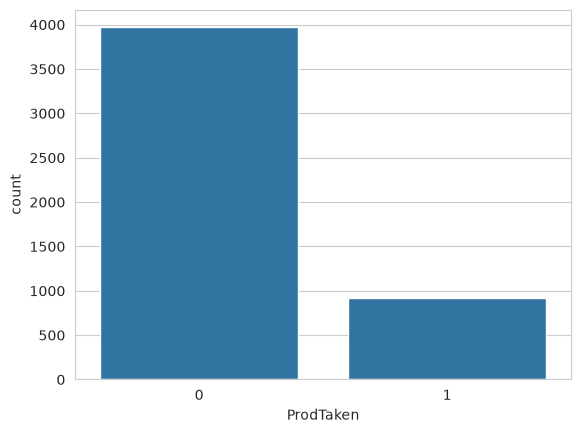

In [9]:
# Distribución de la variable objetivo
print(df['ProdTaken'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='ProdTaken')
plt.show()

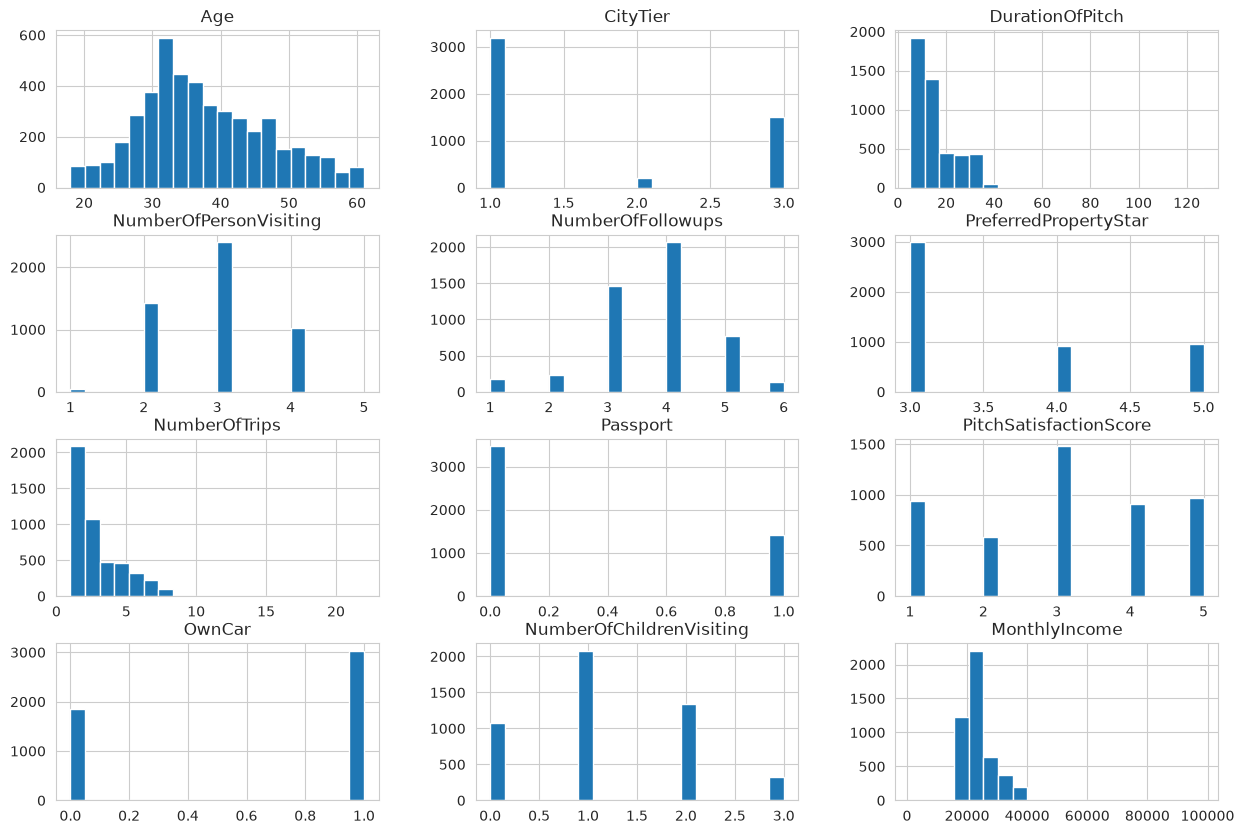

In [10]:
# Histogramas de las variables numéricas
df.drop(columns=['CustomerID','ProdTaken']).hist(bins=20, figsize=(15,10))
plt.show()

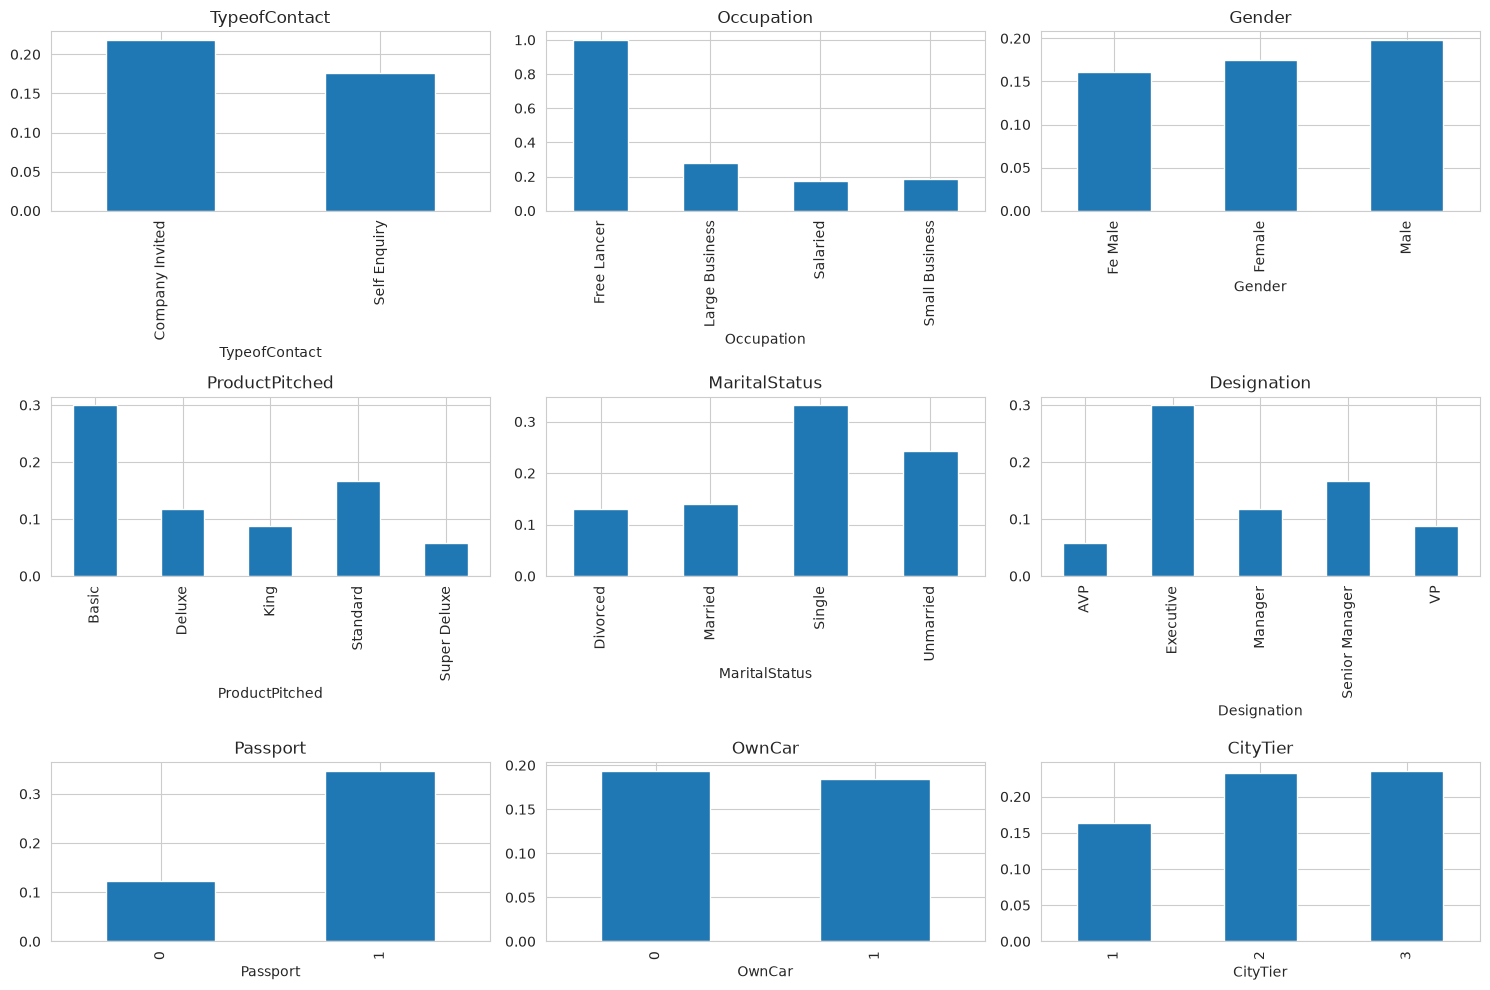

In [11]:
# Tasa de compra por cada variable categórica
cats = ['TypeofContact','Occupation','Gender','ProductPitched','MaritalStatus','Designation','Passport','OwnCar','CityTier']
fig, axes = plt.subplots(3, 3, figsize=(15,10))
for ax, c in zip(axes.ravel(), cats):
    df.groupby(c)['ProdTaken'].mean().plot.bar(ax=ax, title=c)
plt.tight_layout()
plt.show()

In [12]:
# ProductPitched contra Designation
pd.crosstab(df['ProductPitched'], df['Designation'])

Designation,AVP,Executive,Manager,Senior Manager,VP
ProductPitched,,,,,
Basic,0,1842,0,0,0
Deluxe,0,0,1732,0,0
King,0,0,0,0,230
Standard,0,0,0,742,0
Super Deluxe,342,0,0,0,0


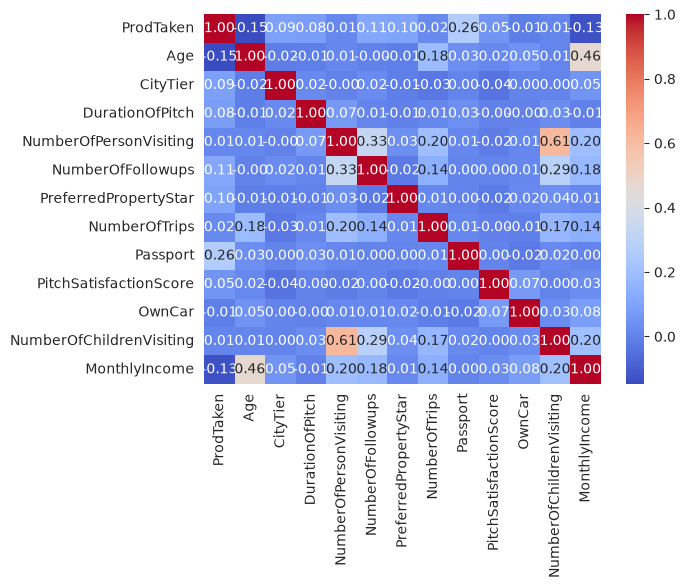

In [13]:
# Correlación entre numéricas
sns.heatmap(df.select_dtypes('number').drop(columns='CustomerID').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

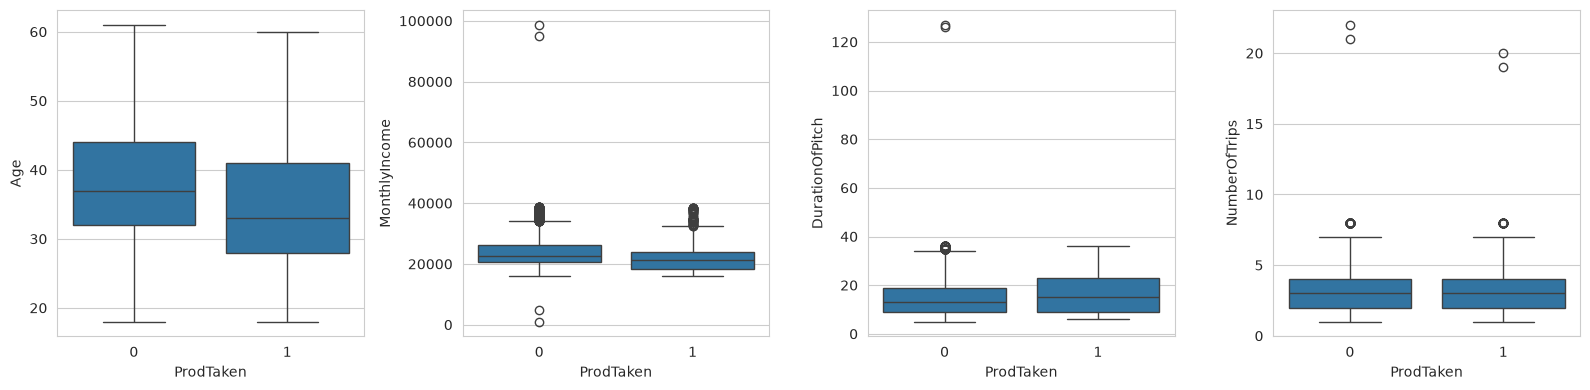

In [14]:
# Boxplots de las numéricas con más valores extremos contra el objetivo
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, c in zip(axes, ['Age','MonthlyIncome','DurationOfPitch','NumberOfTrips']):
    sns.boxplot(data=df, x='ProdTaken', y=c, ax=ax)
plt.tight_layout()
plt.show()

**Hallazgos del análisis exploratorio**

- Solo **18.8 %** de los clientes compró: hay desbalance de clases (por eso los modelos usan `class_weight='balanced'` y no evaluamos solo con accuracy).
- Hay nulos en **8** variables, todas con menos de 5.2 % de faltantes, así que se imputan en lugar de eliminar filas.
- `Gender` tiene un error de captura (*Fe Male*) y `Occupation` tiene solo 2 casos de Free Lancer.
- `ProductPitched` y `Designation` son exactamente la misma información (la tabla cruzada es diagonal), entonces se elimina una.
- **Estadística descriptiva:** el cliente típico tiene 36 años (18 a 61), ingreso mensual mediano de 22,347 y recibió una presentación de 13 minutos. `MonthlyIncome` (1,000 a 98,678), `DurationOfPitch` (máximo 127 min) y `NumberOfTrips` (máximo 22) tienen valores extremos muy lejos del resto.
- **Histogramas:** `Age` es casi simétrica; `MonthlyIncome`, `DurationOfPitch` y `NumberOfTrips` están sesgadas a la derecha. Varias "numéricas" son en realidad discretas con pocos valores (`CityTier`, `Passport`, `OwnCar`, `PreferredPropertyStar`).
- **Correlación:** ninguna variable numérica se relaciona fuerte con el target; la más alta es `Passport` (0.26), seguida de `Age` (−0.15) y `MonthlyIncome` (−0.13). Entre explicativas, las más correlacionadas son `NumberOfPersonVisiting` con `NumberOfChildrenVisiting` (0.61) y `Age` con `MonthlyIncome` (0.46). Como las relaciones lineales son débiles, es razonable probar un modelo no lineal (árbol) además de la regresión logística.
- **Quién compra más:** clientes con pasaporte (34.7 % contra 12.3 %), solteros (33.2 %), más jóvenes (mediana 33 contra 37 años), invitados por la empresa (21.8 % contra 17.6 %) y a los que se les ofreció el paquete Basic (30.0 %).
- **Calidad de los datos:** sin el ID hay 141 filas idénticas, y además la segunda mitad del archivo es casi una copia de la primera con cambios pequeños. Se conservan los registros, pero es una limitación que se retoma en las conclusiones.

## 3. Preparación de los datos

### 3.1 Limpieza y definición del target
Se corrige `Gender`, se quitan `CustomerID` (no aporta) y `Designation` (duplicada de `ProductPitched`). El target es `ProdTaken`. Se separa 80 % entrenamiento / 20 % prueba de forma estratificada **antes** de cualquier transformación, para que nada de la prueba se use al calcular límites, medianas o escalas.

In [15]:
# Corregir Gender y quitar columnas que no aportan (ID y Designation, duplicada de ProductPitched)
data = df.copy()
data['Gender'] = data['Gender'].replace('Fe Male', 'Female')
data = data.drop(columns=['CustomerID','Designation'])

In [16]:
# Definir target y variables, separar train y test estratificado
X = data.drop(columns='ProdTaken')
y = data['ProdTaken']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(X_train.shape, X_test.shape)

(3910, 17) (978, 17)


### 3.2 Outliers
Se detectan con la regla del rango intercuartil (IQR): un valor es extremo si está fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. Los límites se calculan solo con entrenamiento y los valores extremos se **recortan** al límite (no se eliminan filas), tanto en entrenamiento como en prueba.

In [17]:
# Límites IQR calculados con train
cols_out = ['Age','DurationOfPitch','NumberOfTrips','MonthlyIncome']
limites = {}
for c in cols_out:
    q1, q3 = X_train[c].quantile([0.25, 0.75])
    limites[c] = (q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1))
    print(c, 'outliers:', ((X_train[c] < limites[c][0]) | (X_train[c] > limites[c][1])).sum())

Age outliers: 0
DurationOfPitch outliers: 2
NumberOfTrips outliers: 89
MonthlyIncome outliers: 265


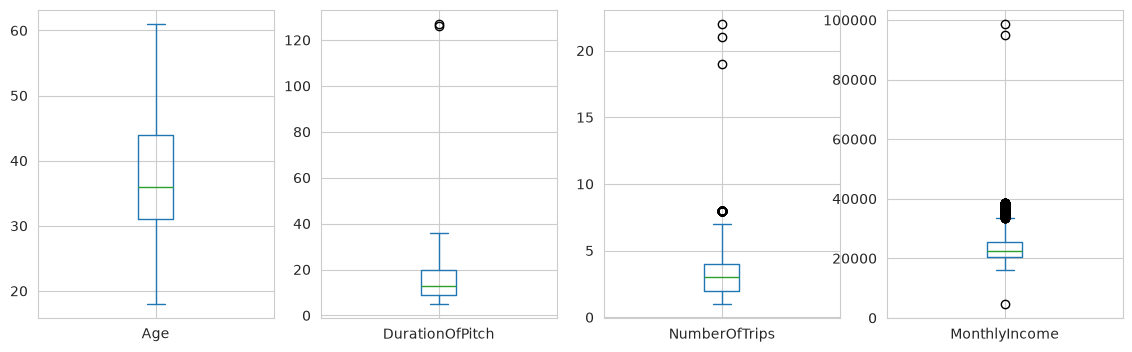

In [18]:
# Boxplots antes del recorte
X_train[cols_out].plot.box(subplots=True, layout=(1,4), figsize=(14,4))
plt.show()

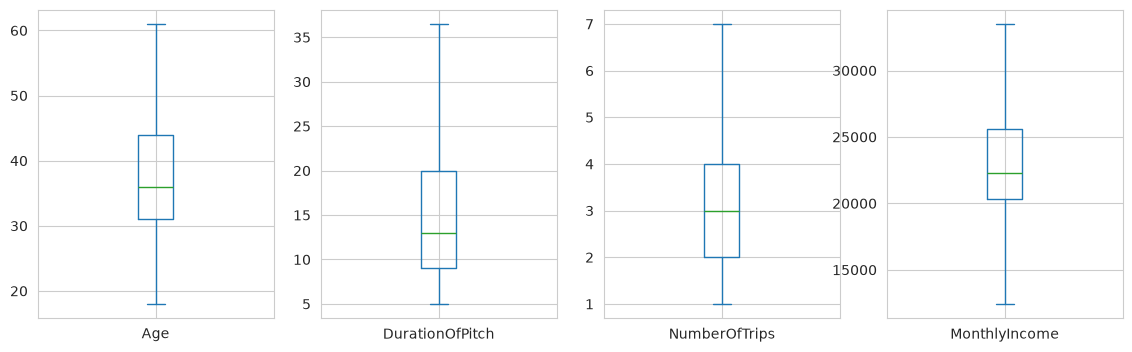

In [19]:
# Recortar outliers en train y test con los límites de train
for c in cols_out:
    X_train[c] = X_train[c].clip(*limites[c])
    X_test[c] = X_test[c].clip(*limites[c])
X_train[cols_out].plot.box(subplots=True, layout=(1,4), figsize=(14,4))
plt.show()

### 3.3 Nulos, codificación y escalamiento
Los tres pasos se hacen con un solo `ColumnTransformer`, ajustado únicamente con entrenamiento:

- **Nulos:** mediana en las numéricas y moda en las categóricas.
- **Codificación:** One-Hot en las categóricas, quitando la primera categoría de cada una para no duplicar información.
- **Escalamiento:** `StandardScaler` en las numéricas (media 0, desviación 1), necesario para la regresión logística.

In [20]:
# Preprocesador: imputación + escalamiento (numéricas) e imputación + One-Hot (categóricas)
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

In [21]:
# Ajustar el preprocesador con train y aplicarlo a train y test
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = [n.split('__')[-1] for n in preprocessor.get_feature_names_out()]

Xtr = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
Xte = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)
print('Variables después de codificar:', Xtr.shape[1])
Xtr.head()

Variables después de codificar: 24


,Age,CityTier,DurationOfPitch,NumberOfPersonVisiting,NumberOfFollowups,PreferredPropertyStar,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,MonthlyIncome,TypeofContact_Self Enquiry,Occupation_Large Business,Occupation_Salaried,Occupation_Small Business,Gender_Male,ProductPitched_Deluxe,ProductPitched_King,ProductPitched_Standard,ProductPitched_Super Deluxe,MaritalStatus_Married,MaritalStatus_Single,MaritalStatus_Unmarried
619,-0.173791,1.477328,-1.162238,-1.256729,-2.708464,1.775141,-0.700644,-0.64351,0.670552,-1.279276,-1.379190,-0.231218,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1227,-0.173791,-0.711099,-0.914326,0.128223,-0.708068,-0.729659,-0.700644,-0.64351,1.401078,-1.279276,0.964414,-1.055660,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3238,-0.283409,-0.711099,-0.666414,0.128223,0.292129,-0.729659,-0.700644,-0.64351,-0.790500,0.781692,-0.207388,0.662541,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3961,0.045445,-0.711099,1.316882,1.513175,0.292129,0.522741,1.641826,-0.64351,0.670552,-1.279276,0.964414,-0.359699,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
490,0.045445,-0.711099,-1.162238,-1.256729,-0.708068,1.775141,0.470591,-0.64351,-0.790500,0.781692,-0.207388,-1.240933,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [22]:
# Verificar que no quedan nulos y que las numéricas quedaron escaladas
print('Nulos en entrenamiento:', Xtr.isna().sum().sum())
print('Nulos en prueba:', Xte.isna().sum().sum())
Xtr[num_cols].describe().T[['mean','std']].round(3).head()

Nulos en entrenamiento: 0
Nulos en prueba: 0


,mean,std
Age,-0.0,1.0
CityTier,0.0,1.0
DurationOfPitch,0.0,1.0
NumberOfPersonVisiting,-0.0,1.0
NumberOfFollowups,-0.0,1.0


### 3.4 Selección de variables (feature importance)
Se entrena un árbol de decisión con todas las variables y se conservan las que acumulan el 90 % de la importancia (reducción de impureza Gini).

In [23]:
# Importancia de variables con un árbol para feature selection
arbol_fi = DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RS).fit(Xtr, y_train)
imp = plot_importancias(arbol_fi, Xtr.columns)

In [24]:
# Quedarnos con las variables que acumulan el 90 % de la importancia
sel_tree = imp.index[:(imp.cumsum() < 0.90).sum() + 1].tolist()
top2 = imp.index[:2].tolist()
print(len(sel_tree), sel_tree)
print('Top 2:', top2)

13 ['Passport', 'DurationOfPitch', 'Age', 'MonthlyIncome', 'CityTier', 'PitchSatisfactionScore', 'PreferredPropertyStar', 'ProductPitched_Deluxe', 'MaritalStatus_Unmarried', 'NumberOfTrips', 'NumberOfFollowups', 'MaritalStatus_Single', 'Occupation_Large Business']
Top 2: ['Passport', 'DurationOfPitch']


**Resultado de la selección:** 13 variables acumulan el 90 % de la importancia. Las dos primeras (`Passport` y `DurationOfPitch`) se usan para graficar la región de decisión de los modelos, y las 13 (`sel_tree`) para los árboles. Para la regresión logística se hace además una selección propia con VIF y p-values (StatsModels).

## 4. Modelado
Se prueban tres modelos de clasificación: **regresión logística**, **árbol de decisión sin podar** y **árbol de decisión podado**. Cada uno se hace primero con las 2 mejores variables (para dibujar la región de clasificación) y luego con sus variables seleccionadas.

### Funciones auxiliares (usadas en todos los modelos)

In [25]:
# Evaluar un modelo, dibujar su región de clasificación y mostrar su reporte
def evaluar(nombre, modelo, cols):
    return evaluar_clasificador(nombre, modelo, Xtr[cols], y_train, Xte[cols], y_test)

def region(modelo, cols, titulo):
    a, b = Xtr[cols[0]], Xtr[cols[1]]
    xx, yy = np.meshgrid(np.linspace(a.min()-0.5, a.max()+0.5, 300), np.linspace(b.min()-0.5, b.max()+0.5, 300))
    # Convertir a DataFrame con nombres de columnas para evitar el UserWarning de scikit-learn
    grid_df = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=cols)
    Z = modelo.predict(grid_df).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlGn')
    plt.scatter(Xte[cols[0]], Xte[cols[1]], c=y_test, cmap='RdYlGn', edgecolor='k')
    plt.xlabel(cols[0]); plt.ylabel(cols[1]); plt.title(titulo)
    plt.show()

def reporte(modelo, cols):
    pred = modelo.predict(Xte[cols])
    print(classification_report(y_test, pred, target_names=['No compra','Compra']))
    plot_matriz_confusion(y_test, pred, etiquetas=('No', 'Sí'), title=f'Matriz de Confusión - {type(modelo).__name__}')
    if hasattr(modelo, "predict_proba"):
        plot_curva_roc(y_test, modelo.predict_proba(Xte[cols])[:, 1])

res = []

# MODELO 1: REGRESIÓN LOGÍSTICA

### Regresión logística con las 2 mejores variables

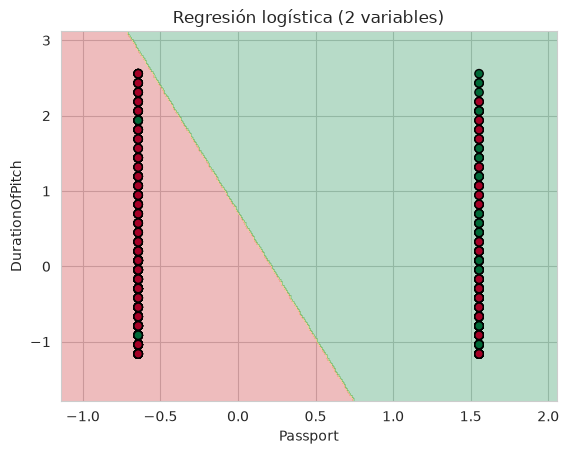

,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652


In [26]:
# Regresión logística con las 2 mejores variables
log2 = LogisticRegression(class_weight='balanced', max_iter=1000).fit(Xtr[top2], y_train)
region(log2, top2, 'Regresión logística (2 variables)')
res.append(evaluar('Logística 2 variables', log2, top2))
pd.DataFrame(res).round(3)

### Selección de variables con VIF
El Factor de Inflación de la Varianza (VIF) detecta variables explicativas muy correlacionadas entre sí (multicolinealidad), que vuelven inestables los coeficientes de la regresión logística. Se elimina de una en una la variable con mayor VIF hasta que todas queden por debajo de 5.

In [27]:
def calcular_vif(df_features):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = df_features.columns
    vif_data["VIF"] = [variance_inflation_factor(df_features.values, i) for i in range(len(df_features.columns))]
    return vif_data.sort_values("VIF", ascending=False)

# VIF inicial de todas las variables procesadas
vif_inicial = calcular_vif(Xtr)
display(vif_inicial.head(10))

,Feature,VIF
14,Occupation_Salaried,494.284395
15,Occupation_Small Business,483.783151
13,Occupation_Large Business,164.441269
11,MonthlyIncome,5.111302
20,ProductPitched_Super Deluxe,3.421943
18,ProductPitched_King,2.986350
19,ProductPitched_Standard,2.625596
21,MaritalStatus_Married,1.833139
17,ProductPitched_Deluxe,1.810151
3,NumberOfPersonVisiting,1.789962


In [28]:
def seleccion_variables_vif(df, threshold=5.0):
    variables = df.columns.tolist()
    while True:
        vif_df = calcular_vif(df[variables])
        max_vif = vif_df.iloc[0]["VIF"]
        if max_vif > threshold:
            peor_variable = vif_df.iloc[0]["Feature"]
            print(f"Eliminando '{peor_variable}' con VIF = {max_vif:.2f}")
            variables.remove(peor_variable)
        else:
            break
    return variables

sel_log = seleccion_variables_vif(Xtr, threshold=5.0)
print("\nVariables después del VIF:", len(sel_log), sel_log)

Eliminando 'Occupation_Salaried' con VIF = 494.28
Eliminando 'MonthlyIncome' con VIF = 5.11

Variables después del VIF: 22 ['Age', 'CityTier', 'DurationOfPitch', 'NumberOfPersonVisiting', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'OwnCar', 'NumberOfChildrenVisiting', 'TypeofContact_Self Enquiry', 'Occupation_Large Business', 'Occupation_Small Business', 'Gender_Male', 'ProductPitched_Deluxe', 'ProductPitched_King', 'ProductPitched_Standard', 'ProductPitched_Super Deluxe', 'MaritalStatus_Married', 'MaritalStatus_Single', 'MaritalStatus_Unmarried']


### StatsModels: coeficientes, p-values y odds ratios

In [29]:
# Modelo Logit de StatsModels con las variables que pasaron el VIF
logit = sm.Logit(y_train, sm.add_constant(Xtr[sel_log])).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:              ProdTaken   No. Observations:                 3910
Model:                          Logit   Df Residuals:                     3887
Method:                           MLE   Df Model:                           22
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.2486
Time:                        23:06:10   Log-Likelihood:                -1421.0
converged:                       True   LL-Null:                       -1891.1
Covariance Type:            nonrobust   LLR p-value:                1.078e-184
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const                          -1.4222      0.172     -8.268      0.000      -1.759      -1.085
Age                            -0.1320      0.055     -2.382      0.017      -0.

In [30]:
# Odds ratios y significancia
tabla = pd.DataFrame({'coef': logit.params, 'odds_ratio': np.exp(logit.params), 'p_value': logit.pvalues}).drop('const')
tabla.sort_values('p_value').round(4)

,coef,odds_ratio,p_value
Passport,0.7522,2.1216,0.0000
ProductPitched_Deluxe,-1.5998,0.2019,0.0000
CityTier,0.5335,1.7049,0.0000
MaritalStatus_Single,1.2641,3.5398,0.0000
ProductPitched_Super Deluxe,-2.4802,0.0837,0.0000
PreferredPropertyStar,0.3403,1.4054,0.0000
NumberOfFollowups,0.3975,1.4880,0.0000
ProductPitched_Standard,-1.0532,0.3488,0.0000
DurationOfPitch,0.3070,1.3593,0.0000
ProductPitched_King,-1.6342,0.1951,0.0000


In [31]:
# Conservar solo las variables significativas (p < 0.05)
sel_log = tabla[tabla['p_value'] < 0.05].index.tolist()
print("Variables finales para la regresión logística:", len(sel_log), sel_log)

Variables finales para la regresión logística: 18 ['Age', 'CityTier', 'DurationOfPitch', 'NumberOfFollowups', 'PreferredPropertyStar', 'NumberOfTrips', 'Passport', 'PitchSatisfactionScore', 'NumberOfChildrenVisiting', 'TypeofContact_Self Enquiry', 'Occupation_Large Business', 'Gender_Male', 'ProductPitched_Deluxe', 'ProductPitched_King', 'ProductPitched_Standard', 'ProductPitched_Super Deluxe', 'MaritalStatus_Single', 'MaritalStatus_Unmarried']


### Regresión logística final

In [32]:
# Ajustar C con validación cruzada de 5 pliegues (métrica F1) usando solo entrenamiento
gs_log = GridSearchCV(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RS),
                      {'C': [0.01, 0.1, 1, 10, 100]}, scoring='f1', cv=5).fit(Xtr[sel_log], y_train)
log_final = gs_log.best_estimator_
print("Mejores parámetros:", gs_log.best_params_, "| F1 en CV:", round(gs_log.best_score_, 3))
res.append(evaluar('Regresión logística', log_final, sel_log))
pd.DataFrame(res).round(3)

Mejores parámetros: {'C': 1} | F1 en CV: 0.542


,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.759,0.723,0.372,0.685,0.482,0.767


In [33]:
# Métricas según el umbral de decisión
proba_log_test = log_final.predict_proba(Xte[sel_log])[:, 1]
plot_metricas_por_umbral(y_test, proba_log_test)

### Evaluación de la regresión logística

In [34]:
# Reporte, matriz de confusión y curva ROC
reporte(log_final, sel_log)

              precision    recall  f1-score   support

   No compra       0.91      0.73      0.81       794
      Compra       0.37      0.68      0.48       184

    accuracy                           0.72       978
   macro avg       0.64      0.71      0.65       978
weighted avg       0.81      0.72      0.75       978



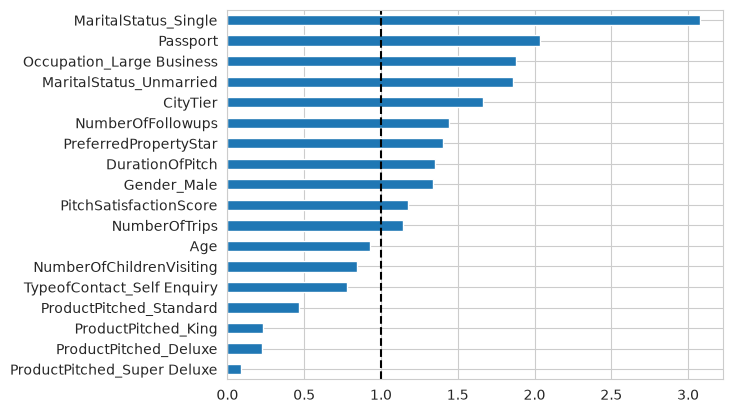

In [35]:
# Odds ratios del modelo final (>1 aumenta la probabilidad de compra, <1 la disminuye)
pd.Series(np.exp(log_final.coef_[0]), index=sel_log).sort_values().plot.barh()
plt.axvline(1, color='k', linestyle='--')
plt.show()

**Resultados de la regresión logística (datos de prueba):** accuracy 0.723, recall 0.685, precisión 0.372, AUC 0.767.

- Detecta a 2 de cada 3 compradores, pero con muchas falsas alarmas (solo 37 % de los que marca como "compra" realmente compran).
- Es el modelo más estable (accuracy de entrenamiento 0.759 contra 0.723 de prueba: casi no sobreajusta) y el más fácil de interpretar. Ser soltero multiplica los odds de compra por ≈3.5 frente a divorciado, y ofrecer cualquier paquete distinto al Basic los reduce. Entre las numéricas, `Passport` es la de mayor efecto (odds ratio ≈2.1); como están escaladas, ese valor es por cada desviación estándar, no por unidad.
- No alcanza los objetivos de accuracy ni de AUC: la relación entre las variables y la compra no es lineal.

# MODELO 2: ÁRBOL DE DECISIÓN SIN PODAR

### Árbol con las 2 mejores variables

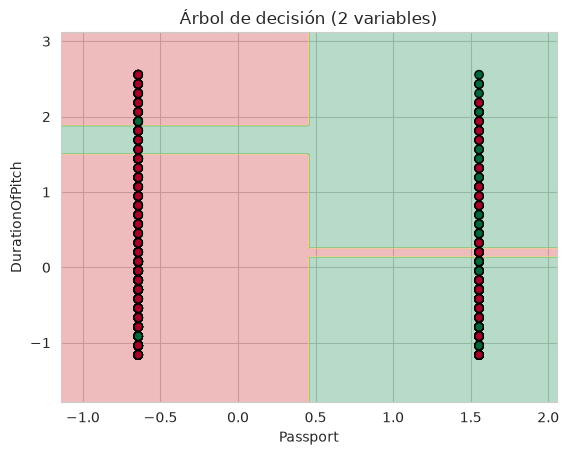

,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.759,0.723,0.372,0.685,0.482,0.767
2,Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649


In [36]:
# Árbol con las 2 mejores variables
arbol2 = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RS).fit(Xtr[top2], y_train)
region(arbol2, top2, 'Árbol de decisión (2 variables)')
res.append(evaluar('Árbol 2 variables', arbol2, top2))
pd.DataFrame(res).round(3)

### Árbol sin podar con las variables seleccionadas

In [37]:
# Árbol sin límite de profundidad con las 13 variables seleccionadas por importancia
arbol_full = DecisionTreeClassifier(class_weight='balanced', random_state=RS).fit(Xtr[sel_tree], y_train)
print('Profundidad:', arbol_full.get_depth(), '| Hojas:', arbol_full.get_n_leaves())
res.append(evaluar('Árbol sin podar', arbol_full, sel_tree))
pd.DataFrame(res).round(3)

Profundidad: 18 | Hojas: 548


,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.759,0.723,0.372,0.685,0.482,0.767
2,Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649
3,Árbol sin podar,1.000,0.895,0.740,0.679,0.708,0.812


In [38]:
# Reporte, matriz de confusión y curva ROC
reporte(arbol_full, sel_tree)

              precision    recall  f1-score   support

   No compra       0.93      0.94      0.94       794
      Compra       0.74      0.68      0.71       184

    accuracy                           0.89       978
   macro avg       0.83      0.81      0.82       978
weighted avg       0.89      0.89      0.89       978



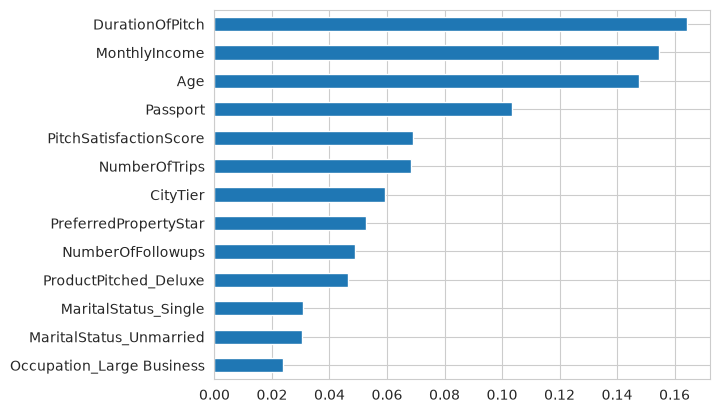

In [39]:
# Importancia de variables del árbol sin podar
pd.Series(arbol_full.feature_importances_, index=sel_tree).sort_values().plot.barh()
plt.show()

**Resultados del árbol sin podar (datos de prueba)**

- Crece hasta 18 niveles y más de 500 hojas, y memoriza el entrenamiento (accuracy de entrenamiento = 1.00). Por su tamaño no se puede leer como reglas.
- Aun así es el que mejor clasifica en prueba: accuracy cercano a 0.90 y precisión cercana a 0.74 (de cada 4 clientes que marca como "compra", 3 sí compran), con recall cercano a 0.68.
- Su AUC (≈0.81) es bajo comparado con su accuracy. La razón es que sus hojas son puras: solo da probabilidades de 0 o 1, así que no puede ordenar a los clientes de más a menos probable.

# MODELO 3: ÁRBOL DE DECISIÓN PODADO

### Diagnóstico de sobreajuste según la profundidad

In [40]:
# Accuracy de entrenamiento y prueba según la profundidad máxima
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15]
acc_tr, acc_te = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=RS).fit(Xtr[sel_tree], y_train)
    acc_tr.append(m.score(Xtr[sel_tree], y_train))
    acc_te.append(m.score(Xte[sel_tree], y_test))

plot_curva_complejidad(depths, acc_tr, acc_te, parametro='max_depth', metrica='Exactitud')

### Poda con GridSearchCV

In [41]:
# Buscar los hiperparámetros de poda con validación cruzada de 5 pliegues (métrica F1) usando solo entrenamiento
params = {'max_depth': [3, 4, 5, 6, 8, 10, 12],
          'min_samples_leaf': [1, 5, 10, 20],
          'ccp_alpha': [0, 0.0005, 0.001, 0.002, 0.005]}
gs = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=RS), params,
                  scoring='f1', cv=5, n_jobs=-1).fit(Xtr[sel_tree], y_train)

arbol_podado = gs.best_estimator_
print("Mejores parámetros:", gs.best_params_, "| F1 en CV:", round(gs.best_score_, 3))
print('Profundidad:', arbol_podado.get_depth(), '| Hojas:', arbol_podado.get_n_leaves())

res.append(evaluar('Árbol podado', arbol_podado, sel_tree))
pd.DataFrame(res).round(3)

Mejores parámetros: {'ccp_alpha': 0, 'max_depth': 12, 'min_samples_leaf': 1} | F1 en CV: 0.638
Profundidad: 12 | Hojas: 413


,Modelo,Acc train,Acc test,Precision,Recall,F1,AUC
0,Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
1,Regresión logística,0.759,0.723,0.372,0.685,0.482,0.767
2,Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649
3,Árbol sin podar,1.000,0.895,0.740,0.679,0.708,0.812
4,Árbol podado,0.956,0.852,0.587,0.717,0.645,0.815


### Evaluación e interpretación del árbol podado

In [42]:
# Reporte, matriz de confusión y curva ROC
reporte(arbol_podado, sel_tree)

              precision    recall  f1-score   support

   No compra       0.93      0.88      0.91       794
      Compra       0.59      0.72      0.65       184

    accuracy                           0.85       978
   macro avg       0.76      0.80      0.78       978
weighted avg       0.87      0.85      0.86       978



Predicciones iguales a las del árbol podado en prueba: 99.8%


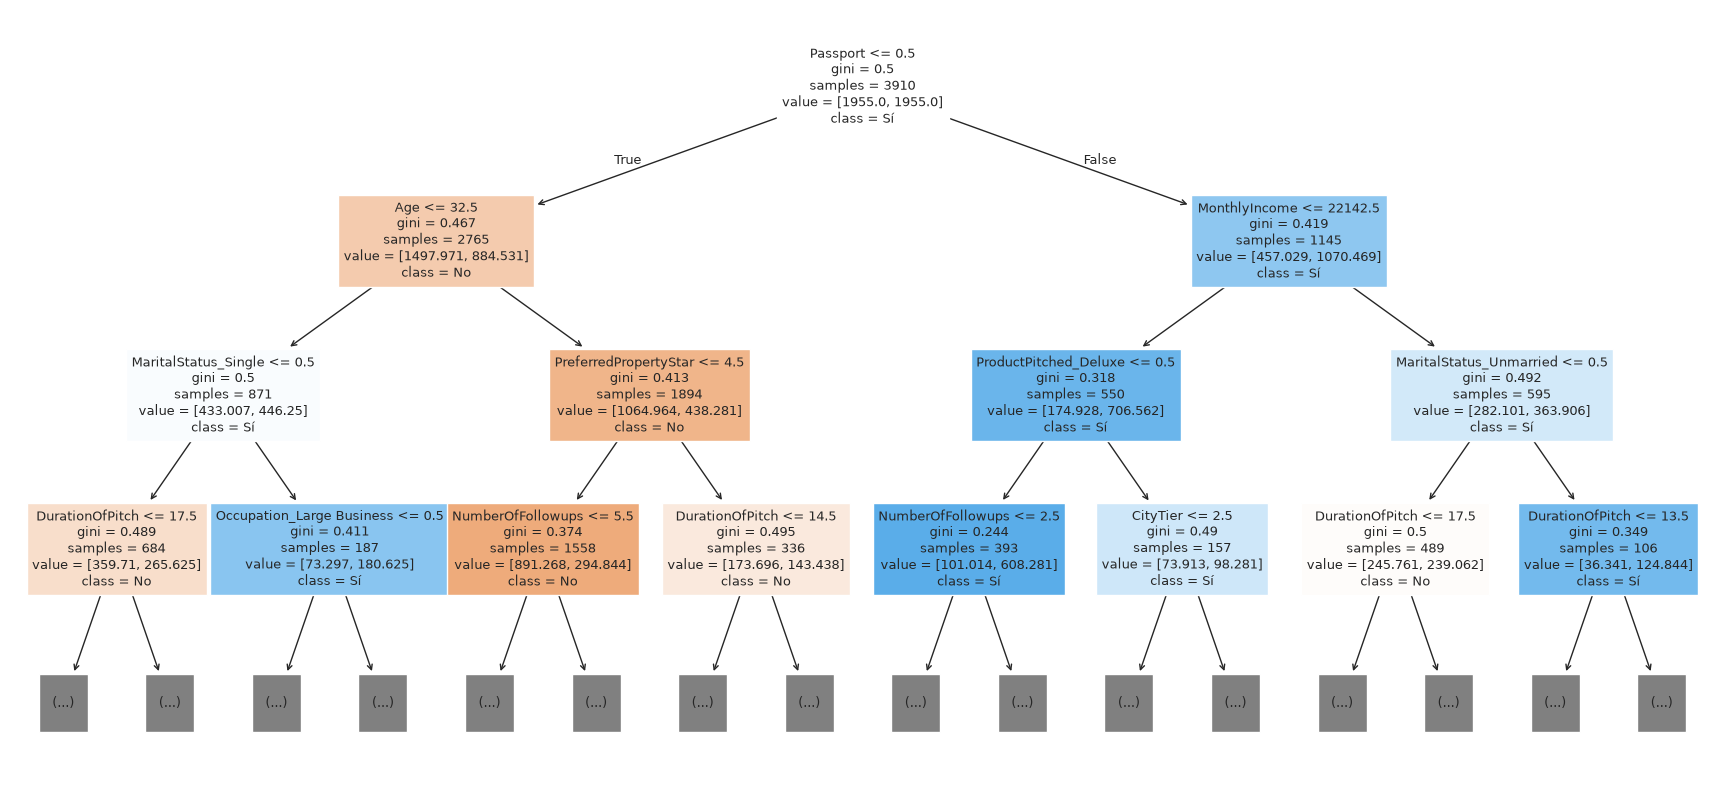

In [43]:
# Para leer las reglas en unidades reales (años, minutos, pesos) se regresan las numéricas a su escala original.
# Un árbol no cambia con el escalamiento, así que es el mismo árbol con los cortes en unidades originales.
escalador = preprocessor.named_transformers_['num'].named_steps['scaler']
Xtr_orig, Xte_orig = Xtr.copy(), Xte.copy()
Xtr_orig[num_cols] = escalador.inverse_transform(Xtr[num_cols])
Xte_orig[num_cols] = escalador.inverse_transform(Xte[num_cols])

arbol_vis = clone(arbol_podado).fit(Xtr_orig[sel_tree], y_train)
iguales = (arbol_vis.predict(Xte_orig[sel_tree]) == arbol_podado.predict(Xte[sel_tree])).mean()
print(f'Predicciones iguales a las del árbol podado en prueba: {iguales:.1%}')

plt.figure(figsize=(22,10))
plot_tree(arbol_vis, feature_names=sel_tree, class_names=['No','Sí'], filled=True, max_depth=3, fontsize=9)
plt.show()

In [44]:
# Reglas del árbol podado (primeros niveles, en unidades originales)
print(export_text(arbol_vis, feature_names=sel_tree, max_depth=3, decimals=1))

|--- Passport <= 0.5
|   |--- Age <= 32.5
|   |   |--- MaritalStatus_Single <= 0.5
|   |   |   |--- DurationOfPitch <= 17.5
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- DurationOfPitch >  17.5
|   |   |   |   |--- truncated branch of depth 9
|   |   |--- MaritalStatus_Single >  0.5
|   |   |   |--- Occupation_Large Business <= 0.5
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- Occupation_Large Business >  0.5
|   |   |   |   |--- truncated branch of depth 6
|   |--- Age >  32.5
|   |   |--- PreferredPropertyStar <= 4.5
|   |   |   |--- NumberOfFollowups <= 5.5
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- NumberOfFollowups >  5.5
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- PreferredPropertyStar >  4.5
|   |   |   |--- DurationOfPitch <= 14.5
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- DurationOfPitch >  14.5
|   |   |   |   |--- truncated branch of depth 9
|--- Passport >  0.5
|   |--- M

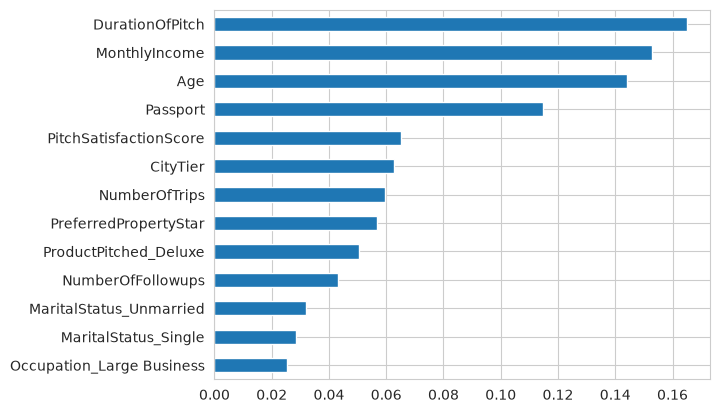

In [45]:
# Importancia de variables del árbol podado
pd.Series(arbol_podado.feature_importances_, index=sel_tree).sort_values().plot.barh()
plt.show()

**Resultados del árbol podado**

- La búsqueda eligió la opción **menos podada** de la malla (`max_depth = 12`, `ccp_alpha = 0`, `min_samples_leaf = 1`): la validación cruzada premia a los árboles profundos. El resultado tiene unas 400 hojas en lugar de más de 500, así que es una poda ligera.
- Frente al árbol sin podar gana un poco de recall (≈0.71), pero pierde accuracy y precisión: marca a más clientes como "compra" y se equivoca más.
- Los primeros niveles sí se pueden leer. El primer corte es **tener pasaporte**; entre quienes no lo tienen, el siguiente corte es la **edad** (≈32 años), y entre quienes sí, el **ingreso mensual** (≈22 mil). Después aparecen el estado civil, la duración de la presentación y el número de seguimientos.

## 5. Evaluación

### Comparación de los modelos en datos de prueba

In [46]:
# Tabla comparativa en datos de prueba
orden = ['Logística 2 variables', 'Árbol 2 variables', 'Regresión logística', 'Árbol podado', 'Árbol sin podar']
comp = pd.DataFrame(res).set_index('Modelo').loc[orden].round(3)
comp

,Acc train,Acc test,Precision,Recall,F1,AUC
Modelo,,,,,,
Logística 2 variables,0.725,0.715,0.329,0.495,0.395,0.652
Árbol 2 variables,0.714,0.702,0.315,0.495,0.385,0.649
Regresión logística,0.759,0.723,0.372,0.685,0.482,0.767
Árbol podado,0.956,0.852,0.587,0.717,0.645,0.815
Árbol sin podar,1.000,0.895,0.740,0.679,0.708,0.812


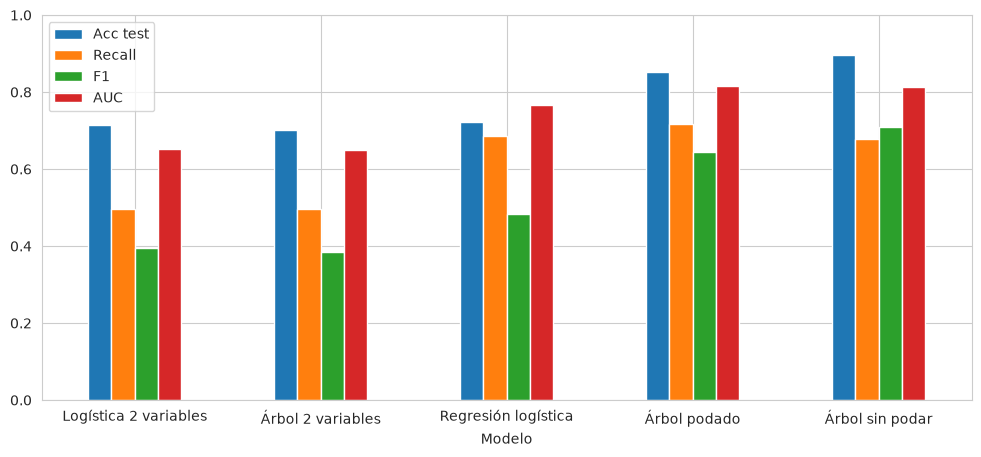

In [47]:
# Gráfica comparativa
comp[['Acc test','Recall','F1','AUC']].plot.bar(figsize=(12,5))
plt.xticks(rotation=0); plt.ylim(0,1)
plt.show()

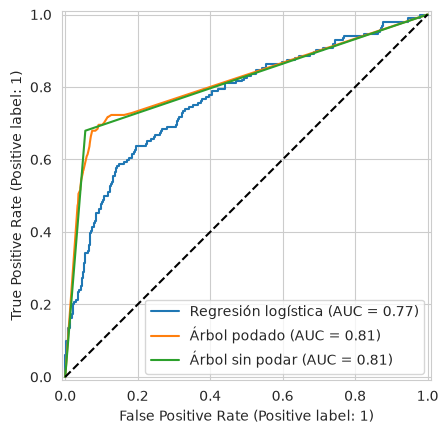

In [48]:
# Curvas ROC de los 3 modelos, cada uno con sus variables
fig, ax = plt.subplots()
for nombre, m, cols in [('Regresión logística', log_final, sel_log), ('Árbol podado', arbol_podado, sel_tree), ('Árbol sin podar', arbol_full, sel_tree)]:
    RocCurveDisplay.from_estimator(m, Xte[cols], y_test, name=nombre, ax=ax)
ax.plot([0,1],[0,1],'k--')
plt.show()

In [49]:
# Cumplimiento de los objetivos planteados en el entendimiento del negocio
obj = comp.loc[['Regresión logística', 'Árbol podado', 'Árbol sin podar'], ['Acc test', 'AUC', 'Recall']]
pd.DataFrame({'Accuracy ≥ 0.85': obj['Acc test'] >= 0.85, 'AUC ≥ 0.85': obj['AUC'] >= 0.85, 'Recall ≥ 0.60': obj['Recall'] >= 0.60}).replace({True: 'Sí', False: 'No'})

,Accuracy ≥ 0.85,AUC ≥ 0.85,Recall ≥ 0.60
Modelo,,,
Regresión logística,No,No,Sí
Árbol podado,Sí,No,Sí
Árbol sin podar,Sí,No,Sí


### Validación cruzada de 10 pliegues
Cada modelo se vuelve a entrenar y evaluar 10 veces con particiones estratificadas, usando exactamente las variables con las que se entrenó. Se presenta con los **datos de prueba** (lo que pide la evaluación) y, como referencia, con los de entrenamiento.

In [50]:
# Validación cruzada de 10 pliegues con las variables seleccionadas de cada modelo
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RS)
scoring = {'Accuracy':'accuracy', 'Precision':'precision', 'Recall':'recall', 'F1':'f1', 'AUC':'roc_auc'}

def tabla_cv(modelo, cols, X_datos, y_datos):
    r = cross_validate(modelo, X_datos[cols], y_datos, cv=cv10, scoring=scoring, n_jobs=-1)
    t = pd.DataFrame({k: r['test_'+k] for k in scoring}, index=[f'Pliegue {i}' for i in range(1,11)])
    media, desv = t.mean(), t.std()
    t.loc['Media'] = media
    t.loc['Desv. Est.'] = desv
    return t.round(3)

#### Regresión logística

In [51]:
# Regresión logística: 10 pliegues con los datos de prueba
cv_log_test = tabla_cv(log_final, sel_log, Xte, y_test)
cv_log_test

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.694,0.359,0.737,0.483,0.692
Pliegue 2,0.673,0.333,0.684,0.448,0.775
Pliegue 3,0.714,0.364,0.632,0.462,0.728
Pliegue 4,0.755,0.432,0.842,0.571,0.841
Pliegue 5,0.694,0.333,0.667,0.444,0.733
Pliegue 6,0.704,0.359,0.778,0.491,0.744
Pliegue 7,0.694,0.350,0.778,0.483,0.791
Pliegue 8,0.755,0.400,0.667,0.500,0.706
Pliegue 9,0.629,0.275,0.611,0.379,0.695
Pliegue 10,0.753,0.400,0.667,0.500,0.722


In [52]:
# Regresión logística: 10 pliegues con los datos de entrenamiento
cv_log_train = tabla_cv(log_final, sel_log, Xtr, y_train)
cv_log_train

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.749,0.411,0.795,0.542,0.815
Pliegue 2,0.806,0.488,0.863,0.624,0.877
Pliegue 3,0.777,0.444,0.753,0.558,0.827
Pliegue 4,0.724,0.374,0.712,0.491,0.791
Pliegue 5,0.742,0.398,0.716,0.512,0.825
Pliegue 6,0.783,0.457,0.784,0.577,0.827
Pliegue 7,0.762,0.420,0.676,0.518,0.796
Pliegue 8,0.772,0.444,0.797,0.570,0.865
Pliegue 9,0.701,0.345,0.649,0.451,0.759
Pliegue 10,0.747,0.409,0.757,0.531,0.831


#### Árbol podado

In [53]:
# Árbol podado: 10 pliegues con los datos de prueba
cv_pod_test = tabla_cv(arbol_podado, sel_tree, Xte, y_test)
cv_pod_test

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.816,0.529,0.474,0.500,0.703
Pliegue 2,0.724,0.367,0.579,0.449,0.699
Pliegue 3,0.857,0.647,0.579,0.611,0.766
Pliegue 4,0.867,0.688,0.579,0.629,0.751
Pliegue 5,0.786,0.444,0.667,0.533,0.763
Pliegue 6,0.786,0.421,0.444,0.432,0.656
Pliegue 7,0.694,0.269,0.389,0.318,0.590
Pliegue 8,0.704,0.211,0.222,0.216,0.498
Pliegue 9,0.804,0.474,0.500,0.486,0.703
Pliegue 10,0.784,0.412,0.389,0.400,0.624


In [54]:
# Árbol podado: 10 pliegues con los datos de entrenamiento
cv_pod_train = tabla_cv(arbol_podado, sel_tree, Xtr, y_train)
cv_pod_train

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.870,0.641,0.685,0.662,0.817
Pliegue 2,0.875,0.650,0.712,0.680,0.818
Pliegue 3,0.867,0.611,0.795,0.690,0.861
Pliegue 4,0.895,0.690,0.795,0.739,0.859
Pliegue 5,0.875,0.651,0.730,0.688,0.831
Pliegue 6,0.852,0.593,0.689,0.638,0.801
Pliegue 7,0.864,0.648,0.622,0.634,0.786
Pliegue 8,0.880,0.663,0.743,0.701,0.852
Pliegue 9,0.877,0.651,0.757,0.700,0.840
Pliegue 10,0.867,0.620,0.770,0.687,0.849


#### Árbol sin podar

In [55]:
# Árbol sin podar: 10 pliegues con los datos de prueba
cv_full_test = tabla_cv(arbol_full, sel_tree, Xte, y_test)
cv_full_test

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.827,0.562,0.474,0.514,0.693
Pliegue 2,0.776,0.440,0.579,0.500,0.701
Pliegue 3,0.898,0.765,0.684,0.722,0.817
Pliegue 4,0.878,0.769,0.526,0.625,0.744
Pliegue 5,0.837,0.550,0.611,0.579,0.749
Pliegue 6,0.806,0.462,0.333,0.387,0.623
Pliegue 7,0.745,0.333,0.389,0.359,0.607
Pliegue 8,0.796,0.417,0.278,0.333,0.595
Pliegue 9,0.845,0.600,0.500,0.545,0.712
Pliegue 10,0.784,0.412,0.389,0.400,0.631


In [56]:
# Árbol sin podar: 10 pliegues con los datos de entrenamiento
cv_full_train = tabla_cv(arbol_full, sel_tree, Xtr, y_train)
cv_full_train

,Accuracy,Precision,Recall,F1,AUC
Pliegue 1,0.882,0.680,0.699,0.689,0.812
Pliegue 2,0.900,0.758,0.685,0.719,0.817
Pliegue 3,0.913,0.767,0.767,0.767,0.857
Pliegue 4,0.905,0.725,0.795,0.758,0.863
Pliegue 5,0.903,0.757,0.716,0.736,0.831
Pliegue 6,0.895,0.770,0.635,0.696,0.795
Pliegue 7,0.890,0.746,0.635,0.686,0.792
Pliegue 8,0.898,0.730,0.730,0.730,0.833
Pliegue 9,0.905,0.753,0.743,0.748,0.843
Pliegue 10,0.882,0.667,0.757,0.709,0.834


#### Resumen de medias

In [57]:
# Medias de la validación cruzada de los 3 modelos
pd.DataFrame({'Logística (test)': cv_log_test.loc['Media'], 'Árbol podado (test)': cv_pod_test.loc['Media'], 'Árbol sin podar (test)': cv_full_test.loc['Media'],
              'Logística (train)': cv_log_train.loc['Media'], 'Árbol podado (train)': cv_pod_train.loc['Media'], 'Árbol sin podar (train)': cv_full_train.loc['Media']}).T

,Accuracy,Precision,Recall,F1,AUC
Logística (test),0.707,0.361,0.706,0.476,0.743
Árbol podado (test),0.782,0.446,0.482,0.458,0.675
Árbol sin podar (test),0.819,0.531,0.476,0.497,0.687
Logística (train),0.756,0.419,0.750,0.537,0.821
Árbol podado (train),0.872,0.642,0.730,0.682,0.831
Árbol sin podar (train),0.897,0.735,0.716,0.724,0.828


**Lectura de la validación cruzada**

- **Con los datos de prueba** las métricas bajan respecto a la evaluación directa, sobre todo en los árboles (accuracy ≈0.78–0.82, recall <0.50, AUC <0.70). Aquí cada modelo se entrena con solo ~880 registros en lugar de 3,910, y un árbol profundo necesita muchos datos; además sus resultados varían mucho entre pliegues (desviación del recall ≈0.13).
- **La regresión logística es la más estable:** con pocos datos mantiene el mejor recall (0.706) y el mejor AUC (0.743), con poca variación entre pliegues.
- **Con los datos de entrenamiento** (3,910 registros) los árboles recuperan accuracy de 0.87–0.90 y AUC de ≈0.83, consistentes con la evaluación en prueba.
- En resumen: los árboles clasifican mejor cuando tienen datos suficientes; la logística es peor clasificando pero más robusta.

## 6. Despliegue: conclusiones y análisis de resultados

### Modelos utilizados
- **Regresión logística:** modelo lineal que estima la probabilidad de compra. Variables elegidas con VIF y p-values (18).
- **Árbol de decisión sin podar:** crece hasta que todas las hojas son puras. Usa las 13 variables elegidas por importancia.
- **Árbol de decisión podado:** mismo árbol, limitando profundidad, tamaño de hoja y `ccp_alpha` con GridSearchCV.

### Modelo definitivo: árbol de decisión sin podar
Es el modelo con mejores resultados en los datos de prueba (accuracy ≈0.90, precisión ≈0.74, F1 ≈0.71).

- **Cómo funciona:** parte los datos una y otra vez. En cada nodo prueba todas las variables y todos los cortes posibles, y elige el que deja los dos grupos más "puros" según el índice de Gini (lo más separados posible entre compra y no compra). Repite hasta que cada hoja tiene clientes de una sola clase. Para predecir, un cliente baja por el árbol según sus características y recibe la clase de la hoja donde cae.
- **Desbalance:** con `class_weight='balanced'` cada comprador pesa más que un no comprador (≈4.3 veces), para que el árbol no ignore a la clase minoritaria.
- **Por qué gana aquí:** capta combinaciones que la logística no puede (por ejemplo, pasaporte + ingreso bajo + paquete Basic), y no necesita que las relaciones sean lineales.
- **Su costo:** memoriza el entrenamiento (accuracy 1.00), no es interpretable por su tamaño y solo da probabilidades de 0 o 1, lo que limita su AUC.

### Cumplimiento de objetivos (datos de prueba)
| Objetivo | Resultado del modelo definitivo | ¿Se cumple? |
|---|---|---|
| Accuracy ≥ 85 % | ≈ 90 % | Sí |
| Recall "compra" ≥ 60 % | ≈ 68 % | Sí |
| ROC-AUC ≥ 0.85 | ≈ 0.81 | **No** |

Se cumplen dos de los tres objetivos. Ningún modelo alcanzó el AUC de 0.85: la logística se queda en 0.77 y los árboles en ≈0.81.

### Hallazgos para el negocio
- **Pasaporte** es la variable que más separa: compra 34.7 % de quienes lo tienen contra 12.3 % de quienes no.
- El perfil con más probabilidad de compra es **joven, soltero, con pasaporte, de ciudad Tier 2 o 3**, y al que se le ofrece el paquete **Basic**.
- Lo que hace el vendedor también cuenta: más **seguimientos** y presentaciones más **largas** aumentan la probabilidad de compra.
- Con el modelo definitivo, de cada 4 clientes que el modelo recomienda llamar, 3 compran; llamando sin modelo compra menos de 1 de cada 5.

### Limitaciones
- **Registros casi repetidos:** 2,005 clientes de la segunda mitad del archivo son casi copias de la primera mitad. Al separar entrenamiento y prueba al azar, copias del mismo cliente quedan en ambos lados, lo que favorece a los árboles que memorizan. Los resultados de los árboles deben leerse como optimistas.
- **Validación cruzada:** con menos datos (10 pliegues sobre prueba) los árboles bajan a accuracy ≈0.80 y recall <0.50, mientras que la logística se mantiene. El modelo definitivo depende de tener muchos datos de entrenamiento.
- **AUC:** el objetivo no se alcanzó con estos modelos.

### Siguientes pasos
- Usar el árbol sin podar para priorizar llamadas y la regresión logística para explicar al equipo de ventas qué factores influyen.
- Volver a evaluar con clientes nuevos (sin registros repetidos) antes de confiar en el 90 % de accuracy.
- Probar modelos que combinen muchos árboles para mejorar el AUC.

In [58]:

# Combine training features and target
train_check = X_train[['Passport', 'DurationOfPitch']].copy()
train_check['Target'] = y_train

# Define exception regions from the graph (approximate boundaries)
regions = {
    'Passport = 0, green region': (
        (train_check['Passport'] == 0) &
        (train_check['DurationOfPitch'].between(1.5, 1.9))
    ),
    'Passport = 1, red region': (
        (train_check['Passport'] == 1) &
        (train_check['DurationOfPitch'].between(0.15, 0.25))
    )
}

# Count observations and their actual classes
for name, condition in regions.items():
    subset = train_check[condition]

    print(f"\n{name}")
    print("Total observations:", len(subset))
    print("Class distribution:")
    print(subset['Target'].value_counts())


Passport = 0, green region
Total observations: 0
Class distribution:
Series([], Name: count, dtype: int64)

Passport = 1, red region
Total observations: 0
Class distribution:
Series([], Name: count, dtype: int64)


In [59]:
# Convert standardized boundaries to original values
mean = X_train['DurationOfPitch'].mean()
std = X_train['DurationOfPitch'].std(ddof=0)

# Regions identified in the graph
lower_green = mean + 1.5 * std
upper_green = mean + 1.9 * std

lower_red = mean + 0.15 * std
upper_red = mean + 0.25 * std

# Identify observations
green_region = X_train[
    (X_train['Passport'] == 0) &
    (X_train['DurationOfPitch'].between(lower_green, upper_green))
]

red_region = X_train[
    (X_train['Passport'] == 1) &
    (X_train['DurationOfPitch'].between(lower_red, upper_red))
]

print("Green exception observations:", len(green_region))
print("Red exception observations:", len(red_region))

Green exception observations: 159
Red exception observations: 42


In [60]:
print("Green region:")
print(y_train.loc[green_region.index].value_counts())

print("\nRed region:")
print(y_train.loc[red_region.index].value_counts())

Green region:
ProdTaken
0    130
1     29
Name: count, dtype: int64

Red region:
ProdTaken
0    35
1     7
Name: count, dtype: int64


In [61]:
# Standardize DurationOfPitch
mean = X_train['DurationOfPitch'].mean()
std = X_train['DurationOfPitch'].std(ddof=0)

pitch_z = (X_train['DurationOfPitch'] - mean) / std

# Combine variables and actual outcomes
check = X_train[['Passport']].copy()
check['Pitch_Z'] = pitch_z
check['ProdTaken'] = y_train

# Green exception: Passport = 0, DurationOfPitch Z = 1.5 to 1.9
green = check[
    (check['Passport'] == 0) &
    (check['Pitch_Z'].between(1.5, 1.9))
]

# Red exception: Passport = 1, DurationOfPitch Z = 0.15 to 0.25
red = check[
    (check['Passport'] == 1) &
    (check['Pitch_Z'].between(0.15, 0.25))
]

print("GREEN REGION (Passport = 0)")
print("Total:", len(green))
print(green['ProdTaken'].value_counts())

print("\nRED REGION (Passport = 1)")
print("Total:", len(red))
print(red['ProdTaken'].value_counts())

GREEN REGION (Passport = 0)
Total: 159
ProdTaken
0    130
1     29
Name: count, dtype: int64

RED REGION (Passport = 1)
Total: 42
ProdTaken
0    35
1     7
Name: count, dtype: int64
